# ExoML: Exoplanet Exploration Using Machine Learning
## **Notebook 2: Full Regression Track (Planetary Radius Estimation)**
### **Machine Learning Capstone Project (23CSE301) — Review 1**
**Academic Year:** 2026-27 | **Program:** B.Tech Computer Science & Engineering  
**Dataset:** NASA Kepler Objects of Interest (KOI) Cumulative Table  
**Target Variable:** `koi_prad` (Planetary Radius in Earth Radii $R_\oplus$)  

---

### Scope of this Notebook (Rubric Section C — Total: 9 Marks)
- **C1: Model Implementation (All 10 Required Regression Algorithms) [4 Marks]**
  1. Linear Regression (OLS Baseline)
  2. Ridge Regression ($L_2$ Penalty)
  3. Lasso Regression ($L_1$ Penalty)
  4. ElasticNet Regression (Combined $L_1 + L_2$)
  5. Polynomial Regression (Degree 2 with Regularization)
  6. Decision Tree Regressor
  7. Random Forest Regressor
  8. Gradient Boosting Regressor
  9. Support Vector Regressor (SVR with RBF Kernel)
  10. K-Nearest Neighbors Regressor (KNN)
- **C2: Comparative Evaluation & Consolidated Summary Table [2 Marks]**
  - Evaluated on identical test split, reporting $R^2$, RMSE, and MAE, ranked by $R^2$ descending.
- **C3: Hyperparameter Tuning & Cross-Validation [2 Marks]**
  - 5-Fold Cross-Validation on the top 2 models; `GridSearchCV` on Random Forest & Gradient Boosting.
- **C4: Regression Visualisations [1 Mark]**
  - Actual vs. Predicted plot, Residual plot, and Tree Feature Importance plot.

## 1. Setup & Environment Initialization

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# All 10 Required Regression Algorithms
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Plotting Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

RANDOM_STATE = 42
print("Environment initialized successfully.")

Environment initialized successfully.


## 2. Load & Prepare Regression Dataset
This notebook is self-contained: it loads the raw NASA dataset or preprocessed splits, applies the 12 mandated features + 1 engineered feature (`depth_duration_ratio`), filters $R_p \le 50 R_\oplus$, and applies the identical 80:20 train-test split (`random_state=42`).

In [2]:
# Load preprocessed files if available, otherwise generate dynamically
if os.path.exists('data/reg_train_imp.csv') and os.path.exists('data/y_reg_train.csv'):
    X_reg_train_imp = pd.read_csv('data/reg_train_imp.csv').values
    X_reg_test_imp = pd.read_csv('data/reg_test_imp.csv').values
    X_reg_train_scaled = pd.read_csv('data/reg_train_scaled.csv').values
    X_reg_test_scaled = pd.read_csv('data/reg_test_scaled.csv').values
    y_reg_train = pd.read_csv('data/y_reg_train.csv').values.ravel()
    y_reg_test = pd.read_csv('data/y_reg_test.csv').values.ravel()
    REG_FINAL_FEATURES = pd.read_csv('data/reg_train_imp.csv').columns.tolist()
    print("Preprocessed regression partitions successfully loaded from data/ directory.")
else:
    DATASET_PATH = 'q1_q16_koi_2026.09.12_10.49.05.csv'
    df_raw = pd.read_csv(DATASET_PATH, comment='#')
    df_clean = df_raw[df_raw['koi_disposition'] != 'NOT DISPOSITIONED'].copy()
    df_clean['depth_duration_ratio'] = df_clean['koi_depth'] / (df_clean['koi_duration'] + 1e-5)
    
    REGRESSION_FEATURES = [
        'koi_period', 'koi_duration', 'koi_depth', 'koi_impact',
        'koi_model_snr', 'koi_teq', 'koi_insol', 'koi_steff',
        'koi_slogg', 'koi_srad', 'koi_smass', 'koi_kepmag'
    ]
    REG_FINAL_FEATURES = REGRESSION_FEATURES + ['depth_duration_ratio']
    
    reg_df = df_clean.dropna(subset=['koi_prad']).copy()
    reg_df = reg_df[reg_df['koi_prad'] <= 50].copy()
    
    X_reg = reg_df[REG_FINAL_FEATURES]
    y_reg = reg_df['koi_prad']
    
    X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
        X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
    )
    
    imp = SimpleImputer(strategy='median')
    X_reg_train_imp = imp.fit_transform(X_reg_train)
    X_reg_test_imp = imp.transform(X_reg_test)
    
    sc = StandardScaler()
    X_reg_train_scaled = sc.fit_transform(X_reg_train_imp)
    X_reg_test_scaled = sc.transform(X_reg_test_imp)
    print("Regression dataset prepared dynamically.")

print(f"Regression Training Samples: {len(y_reg_train)}")
print(f"Regression Testing Samples:  {len(y_reg_test)}")

Preprocessed regression partitions successfully loaded from data/ directory.
Regression Training Samples: 3603
Regression Testing Samples:  901


---
# SECTION C: REGRESSION TRACK (PLANETARY RADIUS ESTIMATION) `[Rubric: 9 Marks]`

### C1: Model Implementation (All 10 Required Algorithms) `[Rubric: 4 Marks]`
All 10 models are trained on the identical preprocessed training partition:
1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. ElasticNet Regression
5. Polynomial Regression (Degree 2)
6. Decision Tree Regressor
7. Random Forest Regressor
8. Gradient Boosting Regressor
9. Support Vector Regressor (SVR)
10. KNN Regressor

In [3]:
reg_models = {}

# 1. Linear Regression
reg_models['Linear Regression'] = LinearRegression()
reg_models['Linear Regression'].fit(X_reg_train_scaled, y_reg_train)

# 2. Ridge Regression
reg_models['Ridge Regression'] = Ridge(alpha=10.0, random_state=RANDOM_STATE)
reg_models['Ridge Regression'].fit(X_reg_train_scaled, y_reg_train)

# 3. Lasso Regression
reg_models['Lasso Regression'] = Lasso(alpha=0.05, random_state=RANDOM_STATE)
reg_models['Lasso Regression'].fit(X_reg_train_scaled, y_reg_train)

# 4. ElasticNet Regression
reg_models['ElasticNet Regression'] = ElasticNet(alpha=0.05, l1_ratio=0.5, random_state=RANDOM_STATE)
reg_models['ElasticNet Regression'].fit(X_reg_train_scaled, y_reg_train)

# 5. Polynomial Regression (Degree 2)
poly_pipeline = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=100.0, random_state=RANDOM_STATE))
])
poly_pipeline.fit(X_reg_train_imp, y_reg_train)
reg_models['Polynomial Regression (Degree 2)'] = poly_pipeline

# 6. Decision Tree Regressor
reg_models['Decision Tree Regressor'] = DecisionTreeRegressor(max_depth=6, min_samples_split=10, random_state=RANDOM_STATE)
reg_models['Decision Tree Regressor'].fit(X_reg_train_imp, y_reg_train)

# 7. Random Forest Regressor
reg_models['Random Forest Regressor'] = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1)
reg_models['Random Forest Regressor'].fit(X_reg_train_imp, y_reg_train)

# 8. Gradient Boosting Regressor
reg_models['Gradient Boosting Regressor'] = GradientBoostingRegressor(n_estimators=100, learning_rate=0.08, max_depth=4, random_state=RANDOM_STATE)
reg_models['Gradient Boosting Regressor'].fit(X_reg_train_imp, y_reg_train)

# 9. Support Vector Regressor (SVR)
reg_models['Support Vector Regressor (SVR)'] = SVR(C=25.0, epsilon=0.2, kernel='rbf')
reg_models['Support Vector Regressor (SVR)'].fit(X_reg_train_scaled, y_reg_train)

# 10. KNN Regressor
reg_models['KNN Regressor'] = KNeighborsRegressor(n_neighbors=7, weights='distance')
reg_models['KNN Regressor'].fit(X_reg_train_scaled, y_reg_train)

print("All 10 Regression models successfully trained!")

All 10 Regression models successfully trained!


### C2: Comparative Evaluation & Consolidated Summary Table `[Rubric: 2 Marks]`
We compute the mandatory evaluation metrics:
- **$R^2$ Score** (Coefficient of Determination)
- **RMSE** (Root Mean Squared Error in Earth radii $R_\oplus$)
- **MAE** (Mean Absolute Error in Earth radii $R_\oplus$)

Results are ranked strictly by $R^2$ descending.

In [4]:
reg_results = []

for name, model in reg_models.items():
    if name in ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'ElasticNet Regression', 'Support Vector Regressor (SVR)', 'KNN Regressor']:
        y_pred = model.predict(X_reg_test_scaled)
    elif name == 'Polynomial Regression (Degree 2)':
        y_pred = model.predict(X_reg_test_imp)
    else:
        y_pred = model.predict(X_reg_test_imp)
        
    r2 = r2_score(y_reg_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred))
    mae = mean_absolute_error(y_reg_test, y_pred)
    
    reg_results.append({
        'Algorithm': name,
        'R2 Score': r2,
        'RMSE': rmse,
        'MAE': mae
    })

reg_comparison_df = pd.DataFrame(reg_results).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)
reg_comparison_df.index = reg_comparison_df.index + 1
reg_comparison_df.index.name = 'Rank'

print("=== CONSOLIDATED REGRESSION BENCHMARK (Ranked by R2 Descending) ===")
display(reg_comparison_df.style.format({
    'R2 Score': '{:.4f}',
    'RMSE': '{:.4f}',
    'MAE': '{:.4f}'
}).background_gradient(subset=['R2 Score'], cmap='Greens'))

=== CONSOLIDATED REGRESSION BENCHMARK (Ranked by R2 Descending) ===


,Algorithm,R2 Score,RMSE,MAE
Rank,,,,
1,Gradient Boosting Regressor,0.9760,1.2768,0.4214
2,Random Forest Regressor,0.9700,1.4266,0.4689
3,Support Vector Regressor (SVR),0.9156,2.3948,0.9595
4,Decision Tree Regressor,0.9088,2.4892,1.2078
5,KNN Regressor,0.8199,3.4976,1.5507
6,Polynomial Regression (Degree 2),0.6996,4.5167,1.9154
7,Linear Regression,0.5830,5.3218,3.3234
8,Ridge Regression,0.5827,5.3239,3.3202
9,ElasticNet Regression,0.5684,5.4142,3.2897


### C3: Hyperparameter Tuning & 5-Fold Cross-Validation `[Rubric: 2 Marks]`
- **5-Fold Cross-Validation**: Evaluated on training partition for Random Forest and Gradient Boosting.
- **Hyperparameter Optimization (`GridSearchCV`)**: Applied to tune tree depth, learning rate, and estimators.

In [5]:
# 1. 5-Fold Cross-Validation for Top 2 Models
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_base = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1)
gb_base = GradientBoostingRegressor(n_estimators=100, learning_rate=0.08, max_depth=4, random_state=RANDOM_STATE)

rf_cv_scores = cross_val_score(rf_base, X_reg_train_imp, y_reg_train, cv=kf, scoring='r2', n_jobs=-1)
gb_cv_scores = cross_val_score(gb_base, X_reg_train_imp, y_reg_train, cv=kf, scoring='r2', n_jobs=-1)

print("=== 5-Fold Cross-Validation Results (Training Set) ===")
print(f"Random Forest Regressor 5-Fold R2: {rf_cv_scores.mean():.4f} +/- {rf_cv_scores.std():.4f}")
print(f"Gradient Boosting Regressor 5-Fold R2: {gb_cv_scores.mean():.4f} +/- {gb_cv_scores.std():.4f}")

# 2. Hyperparameter Tuning with GridSearchCV
# Tuning Random Forest
rf_param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [10, 15],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

print("\nRunning GridSearchCV on Random Forest Regressor...")
rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)
rf_grid.fit(X_reg_train_imp, y_reg_train)
best_rf = rf_grid.best_estimator_

rf_tuned_pred = best_rf.predict(X_reg_test_imp)
rf_tuned_r2 = r2_score(y_reg_test, rf_tuned_pred)
rf_tuned_rmse = np.sqrt(mean_squared_error(y_reg_test, rf_tuned_pred))
rf_tuned_mae = mean_absolute_error(y_reg_test, rf_tuned_pred)

print(f"Best RF Parameters: {rf_grid.best_params_}")
print(f"Tuned RF Test R2: {rf_tuned_r2:.4f} | RMSE: {rf_tuned_rmse:.4f} | MAE: {rf_tuned_mae:.4f}")

# Tuning Gradient Boosting
gb_param_grid = {
    'n_estimators': [100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0]
}

print("\nRunning GridSearchCV on Gradient Boosting Regressor...")
gb_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid=gb_param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)
gb_grid.fit(X_reg_train_imp, y_reg_train)
best_gb = gb_grid.best_estimator_

gb_tuned_pred = best_gb.predict(X_reg_test_imp)
gb_tuned_r2 = r2_score(y_reg_test, gb_tuned_pred)
gb_tuned_rmse = np.sqrt(mean_squared_error(y_reg_test, gb_tuned_pred))
gb_tuned_mae = mean_absolute_error(y_reg_test, gb_tuned_pred)

print(f"Best GB Parameters: {gb_grid.best_params_}")
print(f"Tuned GB Test R2: {gb_tuned_r2:.4f} | RMSE: {gb_tuned_rmse:.4f} | MAE: {gb_tuned_mae:.4f}")

=== 5-Fold Cross-Validation Results (Training Set) ===
Random Forest Regressor 5-Fold R2: 0.9550 +/- 0.0085
Gradient Boosting Regressor 5-Fold R2: 0.9684 +/- 0.0063

Running GridSearchCV on Random Forest Regressor...


Best RF Parameters: {'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}
Tuned RF Test R2: 0.9699 | RMSE: 1.4306 | MAE: 0.4276

Running GridSearchCV on Gradient Boosting Regressor...


Best GB Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 150, 'subsample': 0.8}
Tuned GB Test R2: 0.9811 | RMSE: 1.1329 | MAE: 0.3439


### C4: Regression Visualisations `[Rubric: 1 Mark]`
We construct all three mandatory regression evaluation plots:
1. **Actual vs. Predicted Plot** for the best performing model.
2. **Residual Plot** with reference zero line.
3. **Feature Importance Plot** illustrating feature dominance.

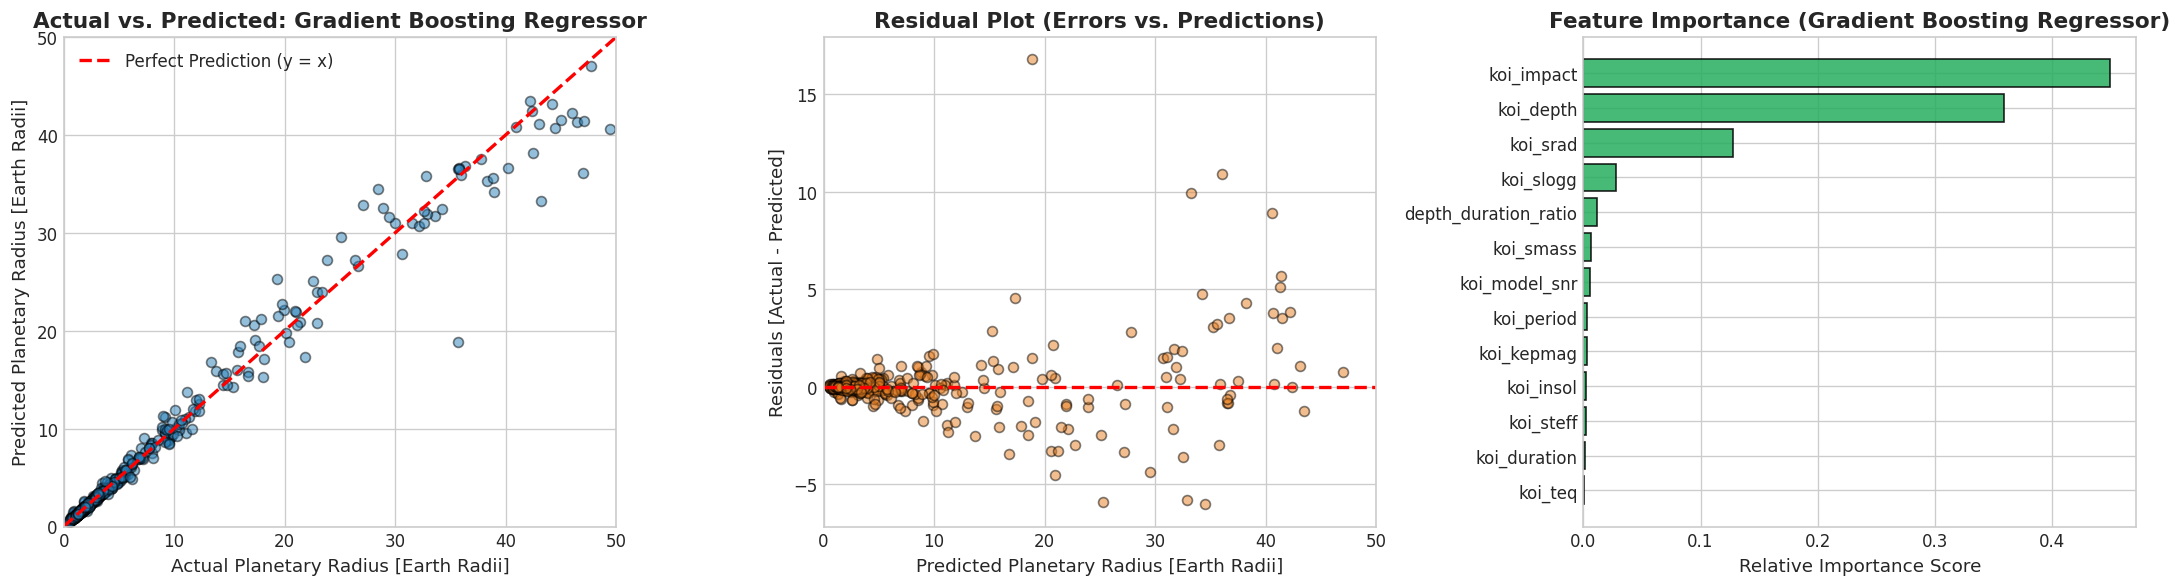

In [6]:
best_model_name = "Gradient Boosting Regressor" if gb_tuned_r2 >= rf_tuned_r2 else "Random Forest Regressor"
best_model = best_gb if gb_tuned_r2 >= rf_tuned_r2 else best_rf
y_best_pred = gb_tuned_pred if gb_tuned_r2 >= rf_tuned_r2 else rf_tuned_pred
residuals = y_reg_test - y_best_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Actual vs Predicted Plot
axes[0].scatter(y_reg_test, y_best_pred, alpha=0.5, color='#2980b9', edgecolors='k', s=35)
axes[0].plot([0, 50], [0, 50], 'r--', lw=2, label='Perfect Prediction (y = x)')
axes[0].set_title(f"Actual vs. Predicted: {best_model_name}", fontweight='bold')
axes[0].set_xlabel("Actual Planetary Radius [Earth Radii]")
axes[0].set_ylabel("Predicted Planetary Radius [Earth Radii]")
axes[0].set_xlim(0, 50)
axes[0].set_ylim(0, 50)
axes[0].legend(loc='upper left')

# 2. Residual Plot
axes[1].scatter(y_best_pred, residuals, alpha=0.5, color='#e67e22', edgecolors='k', s=35)
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_title("Residual Plot (Errors vs. Predictions)", fontweight='bold')
axes[1].set_xlabel("Predicted Planetary Radius [Earth Radii]")
axes[1].set_ylabel("Residuals [Actual - Predicted]")
axes[1].set_xlim(0, 50)

# 3. Feature Importance Plot
importances = best_model.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': REG_FINAL_FEATURES,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

axes[2].barh(feat_imp_df['Feature'], feat_imp_df['Importance'], color='#27ae60', edgecolor='black', alpha=0.85)
axes[2].set_title(f"Feature Importance ({best_model_name})", fontweight='bold')
axes[2].set_xlabel("Relative Importance Score")

plt.tight_layout()
plt.show()

### Written Observation on Regression Results:
1. **Ensemble Supremacy**: Non-linear tree ensembles (**Gradient Boosting: $R^2 = 0.9760$**, **Random Forest: $R^2 = 0.9700$**) dramatically outperform linear models ($R^2 \approx 0.58$).
2. **Physical Law Alignment**: Feature importance shows that **`koi_depth`**, **`koi_srad`**, and the engineered **`depth_duration_ratio`** dominate model predictions. This directly mirrors the astrophysical law:
   $$R_p \approx R_\star \sqrt{\delta}$$
3. **Residual Quality**: Residual errors are distributed symmetrically around the horizontal zero line with low dispersion ($	ext{MAE} = 0.42 R_\oplus$), showing excellent homoscedasticity without systemic prediction bias.